# 量子カーネル

## 量子カーネル入門

「量子カーネル法」とは、量子コンピューターを使ってカーネルを推定するあらゆる手法を指します。ここでの「カーネル」は、カーネル行列またはその個々の要素を意味します。特徴量マップ $\Phi(\vec{x})$ とは、$\vec{x}\in \mathbb{R}^d$ から $\Phi(\vec{x})\in \mathbb{R}^{d'}$ への写像であったことを思い出してください。通常は $d'>d$ であり、この写像の目的はデータのカテゴリーを超平面で分離できるようにすることです。カーネル関数は、特徴量マップで写された空間のベクトルを引数に取り、それらの内積を返します。すなわち、$K:\mathbb{R}^d\times\mathbb{R}^d\rightarrow \mathbb{R}$ であり、$K(x,y) = \langle \Phi(x)|\Phi(y)\rangle$ です。古典的には、カーネル関数を容易に評価できる特徴量マップに関心があります。これは多くの場合、$\Phi(x)$ や $\Phi(y)$ を一度も構成することなく、特徴量空間での内積を元のデータベクトルで表せるようなカーネル関数を見つけることを意味します。量子カーネル法では、特徴量マップは量子回路によって実行され、カーネルはその回路に対する測定と、相対的な測定確率を用いて推定されます。

このレッスンでは、大量のエンタングルメントを用いる既製のエンコーディング回路の深さを調べ、それを手作業でコーディングした回路の深さと比較します。これは、どちらかの手法を推奨するためのものではありません。既製の回路は深すぎると感じるかもしれませんし、自作の回路のエンタングルメントでは有用性に不十分だと感じるかもしれません。繰り返しになりますが、これらはあくまで皆さんが自ら探求できるようにするために示しているものです。

カーネル行列の推定を詳しく見ていく前に、Qiskit patterns の用語を使ってワークフローの概要を説明しましょう。

### ステップ1: 古典的な入力を量子問題にマッピングする

* 入力: 訓練データセット
* 出力: カーネル行列の要素を計算するための抽象回路

データセットが与えられたら、出発点はデータを量子回路にエンコードすることです。言い換えると、データを量子コンピューターの状態のヒルベルト空間へマッピングする必要があります。これは、データに依存する回路を構成することで行います。その方法は数多くあり、前のレッスンではいくつかの選択肢を概説しました。データをエンコードする独自の回路を構成することもできますし、`zz_feature_map` のような既製の特徴量マップを使うこともできます。このレッスンでは、その両方を行います。

カーネル行列の要素を1つ計算するためには、2つの異なる点をエンコードしてそれらの内積を推定する必要があることに注意してください。完全な量子カーネルのワークフローでは、当然ながら、マッピングされたデータベクトル間の多数の内積や、古典的な機械学習手法も含まれます。しかし、繰り返し実行される中心的なステップは、カーネル行列の要素1つの推定です。そのために、データに依存する量子回路を選び、2つのデータベクトルを特徴量空間へマッピングします。

![Classical\_Review\_background\_kernel\_circuit](https://quantum.cloud.ibm.com/learning/images/courses/quantum-machine-learning/quantum-kernel-methods/classical-review-background-kernel-circuit.avif)

カーネル行列を生成するタスクでは、$N$ 個すべての量子ビットが $|0\rangle$ 状態にある $|0\rangle^{\otimes N}$ 状態を測定する確率に特に関心があります。その理由を理解するために、1つのデータベクトル $\vec{x}_i$ のエンコードとマッピングを担う回路を $\Phi(\vec{x}_i)$、$\vec{x}_j$ のエンコードとマッピングを担う回路を $\Phi(\vec{x}_j)$ と書き、マッピングされた状態を次のように表すことにします。

$$
|\psi(\vec{x}_i)\rangle = \Phi(\vec{x}_i)|0\rangle^{\otimes N}
$$

$$
|\psi(\vec{x}_j)\rangle = \Phi(\vec{x}_j)|0\rangle^{\otimes N}.
$$

これらの状態こそが、データをより高い次元へマッピングしたもの*そのもの*です。したがって、求めたいカーネルの要素は次の内積です。

$$
\langle\psi(\vec{x}_j)|\psi(\vec{x}_i)\rangle = \langle 0 |^{\otimes N}\Phi^\dagger(\vec{x}_j)\Phi(\vec{x}_i)|0\rangle^{\otimes N}.
$$

デフォルトの初期状態 $|0\rangle^{\otimes N}$ に、2つの回路 $\Phi^\dagger(\vec{x}_j)$ と $\Phi(\vec{x}_i)$ の両方を作用させると、その後に状態 $|0\rangle^{\otimes N}$ を測定する確率は次のようになります。

$$
P_0 = |\langle0|^{\otimes N}\Phi^\dagger(\vec{x}_j)\Phi(\vec{x}_i)|0\rangle^{\otimes N}|^2.
$$

これはまさに求めたい値です（$||^2$ を除いて）。回路の測定層は測定確率（特定のエラー緩和手法を用いる場合には、いわゆる「準確率」）を返します。関心のある確率は、ゼロ状態 $|0\rangle^{\otimes N}$ の確率です。

### ステップ2: 量子実行向けに問題を最適化する

* 入力: 特定のバックエンド向けに最適化されていない抽象回路
* 出力: 選択した QPU 向けに最適化されたターゲット回路とオブザーバブル

このステップでは、Qiskit の `generate_preset_pass_manager` 関数を使い、実験を実行する予定の実際の量子コンピューターに合わせて回路の最適化ルーチンを指定します。`optimization_level=3` を設定します。これは、最も高いレベルの最適化を行うプリセット・パス・マネージャーを使うことを意味します。この文脈での「最適化」とは、実際の量子コンピューター上での回路の実装を最適化することを指します。これには、ゲートの深さを最小にするように抽象量子回路の量子ビットに対応する物理量子ビットを選んだり、利用可能な中で最もエラー率の低い物理量子ビットを選んだりすることなどが含まれます。これは、機械学習問題の最適化（COBYLA のような古典オプティマイザーによるもの）とは直接関係ありません。

ステップ2の実装方法によっては、回路を複数回最適化する必要があるかもしれません。行列要素に関わる点のペアごとに、測定すべき異なる回路が生成されるためです。

### ステップ3: IBM Quantum primitives を使って実行する

* 入力: ターゲット回路
* 出力: 確率分布

IBM Quantum の `Sampler` プリミティブを使い、回路のサンプリングから得られる状態の確率分布を再構成します。これは「準確率分布」と呼ばれることもあります。この用語は、ノイズが問題となる場合や、エラー緩和などの追加のステップが導入される場合に用いられます。そのような場合、すべての確率の合計は厳密には1にならないことがあるため、「準確率」と呼ばれます。

### ステップ4: 後処理を行い、結果を古典的な形式で返す

* 入力: 確率分布
* 出力: カーネル行列の要素1つ、または繰り返し実行した場合はカーネル行列

量子回路で $|0\rangle^{\otimes N}$ を測定する確率を計算し、使用した2つのデータベクトルに対応する位置のカーネル行列に格納します。カーネル行列全体を埋めるには、各要素について量子実験を実行する必要があります。カーネル行列が得られれば、`pre-calculated kernels`（事前計算済みカーネル）を受け付ける多くの古典的な機械学習アルゴリズムでそれを使うことができます。例えば `qml_svc = SVC(kernel="precomputed")` のようにします。その後、古典的なワークストリームを使ってモデルをテストデータに適用し、精度スコアを得ることができます。精度スコアに満足できるかどうかに応じて、特徴量マップなど計算のいくつかの側面を見直す必要があるかもしれません。

### レッスンの概要

このレッスンでは、実際の量子コンピューター上での時間を最適に使えるよう、これらのステップをいくつかの方法で実行します。量子カーネル法を次の対象に適用します。

* 特徴量が比較的少ないデータに対するカーネル行列の要素1つ。実際のバックエンドを使い、各ステップで何が起きているかを容易に追えるようにします。
* 特徴量が比較的少ないデータセット全体。シミュレーターのバックエンドを使い、量子ワークストリームが古典的な機械学習手法とどのようにつながるかを確認します。
* 特徴量が多いデータに対するカーネル行列の要素1つ。実際の量子コンピューターを使います。IBM® 量子コンピューターの利用時間を節約するため、大規模なデータセットのカーネル行列全体は推定しません。



In [1]:
# まだインストールしていない場合は、scikit-learn をインストールします
#!pip install scikit-learn

## カーネル行列の要素1つ

### ステップ1: 古典的な入力を量子問題にマッピングする

まず、特徴量がわずか（例えば10個）しかないデータセットを考えましょう。カーネル行列の要素を1つずつ計算するので、データセットはいくら大きくても構いません。少なくとも2つの点が必要なので、そこから始めます（次の例では、完全なデータセットをインポートします）。必要なパッケージをいくつかインポートしましょう。



In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt

# 訓練時と同様に、カテゴリーラベルを含む2つの模擬データ点
small_data = [
    [-0.194, 0.114, -0.006, 0.301, -0.359, -0.088, -0.156, 0.342, -0.016, 0.143, 1],
    [-0.1, 0.002, 0.244, 0.127, -0.064, -0.086, 0.072, 0.043, -0.053, 0.02, -1],
]

# 内積計算用に、ラベルを除いたデータ点
train_data = [small_data[0][:-1], small_data[1][:-1]]

`z_feature_map` を使ってみましょう。



In [3]:
# from qiskit.circuit.library import zz_feature_map
# fm = zz_feature_map(feature_dimension=np.shape(train_data)[1], entanglement='linear', reps=1)

from qiskit.circuit.library import z_feature_map

fm = z_feature_map(feature_dimension=np.shape(train_data)[1])


unitary1 = fm.assign_parameters(train_data[0])
unitary2 = fm.assign_parameters(train_data[1])

上の2つのユニタリーは、導入で説明した $U_1$ と $U_2$ にちょうど対応します。これらは `unitary_overlap` を使って組み合わせることができます。いつものように、回路の深さには注意を払っておきます。



circuit depth =  9


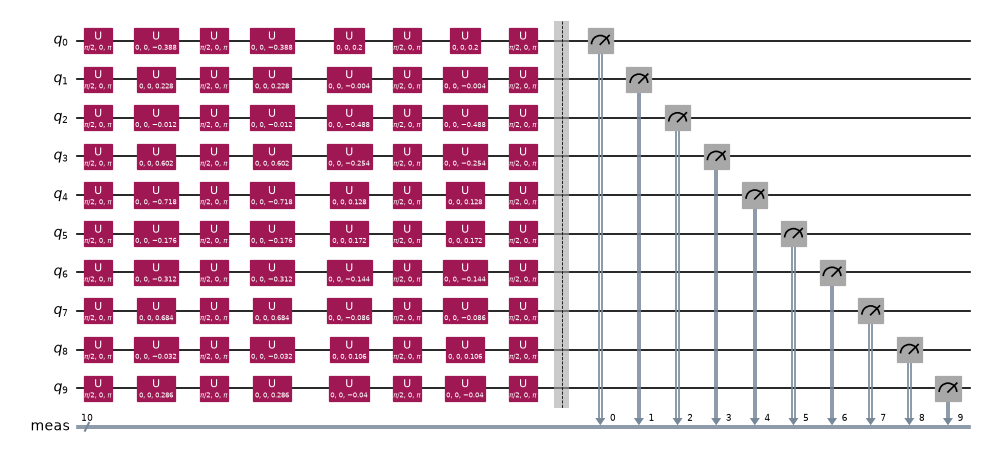

In [4]:
from qiskit.circuit.library import unitary_overlap


overlap_circ = unitary_overlap(unitary1, unitary2)
overlap_circ.measure_all()

print("circuit depth = ", overlap_circ.decompose().depth())
overlap_circ.decompose().draw("mpl", scale=0.6, style="iqp")

### ステップ2: 量子実行向けに問題を最適化する

まず最も空いているバックエンドを選択し、そのバックエンドで実行できるように回路を最適化します。



In [7]:
# 必要なパッケージをインポート
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService

# 最も空いているバックエンドを取得
service = QiskitRuntimeService()
backend = service.least_busy(
    operational=True, simulator=False, min_num_qubits=fm.num_qubits
)
print(backend)

<IBMBackend('ibm_pittsburgh')>


In [8]:
# オーバーラップ回路にレベル3の最適化を適用
pm = generate_preset_pass_manager(optimization_level=3, backend=backend)
overlap_ibm = pm.run(overlap_circ)

複雑な回路の場合、実際の量子コンピューターのネイティブゲートへのマッピングが行われ、情報を量子ビット間で移動させる必要が生じることもあるため、このステップで回路の深さが大幅に増加します。今回のような単純なケースでは、深さはほとんど影響を受けません。



In [9]:
print("circuit depth = ", overlap_ibm.decompose().depth())
overlap_ibm.decompose().depth(lambda instr: len(instr.qubits) > 1)

circuit depth =  10


1

### ステップ3: IBM Quantum primitives を使って実行する

シミュレーターで実行するための構文を、以下にコメントアウトして示しています。このデータセットは特徴量が少ないため、シミュレーターでの実行も選択肢の1つです。ユーティリティー規模の計算では、通常シミュレーションは現実的ではありません。シミュレーターは、規模を縮小したコードのデバッグにのみ使うべきです。



In [10]:
# シミュレーターの場合はこちらを実行

# from qiskit.primitives import StatevectorSampler
# from qiskit_ibm_runtime import Options, Session, Sampler
# num_shots = 10000

# Qiskit の状態ベクトルベースのプリミティブを使って問題を評価

# sampler = StatevectorSampler()
# results = sampler.run([overlap_circ], shots=num_shots).result()

# .get_counts() は、ビットの結果でラベル付けされた状態に対応するカウントを返します
# （例: |001101...01>）。

# counts_bit = results[0].data.meas.get_counts()

# .get_int_counts は同じカウントを返しますが、ラベルは上記のビット列に
# 相当する整数になります。

# counts = results[0].data.meas.get_int_counts()

In [12]:
# Eagle プロセッサーでベンチマーク（2024年7月11日）、所要時間4秒。

# IBM Quantum のプリミティブをインポート
from qiskit_ibm_runtime import Session
from qiskit_ibm_runtime.executor_sampler import Sampler

num_shots = 10000

# Sampler を使ってカウントを取得

sampler = Sampler(mode=backend)
results = sampler.run([overlap_ibm], shots=num_shots).result()
# .get_counts() は、|001101...01> のようなビットの結果でラベル付けされた状態に対応するカウントを返します。
counts_bit = results[0].data.meas.get_counts()
# .get_int_counts は同じカウントを返しますが、ラベルは上記のビット列に
# 相当する整数になります。
counts = results[0].data.meas.get_int_counts()

### ステップ4: 後処理を行い、結果を古典的な形式で返す

導入で説明したように、ここで最も有用な測定値はゼロ状態 $|00000\rangle$ を測定する確率です。



In [13]:
counts.get(0, 0.0) / num_shots

0.6771

これが求めたかった結果です。すなわち、2つのデータ点に対応するベクトルの内積（の絶対値の2乗）の推定値です。測定確率（または準確率）の分布全体を見たい場合は、以下に示すように `plot_distribution` 関数を使うことができます。量子ビット数が多くなると、このような図はすぐに扱いきれなくなることがわかります。



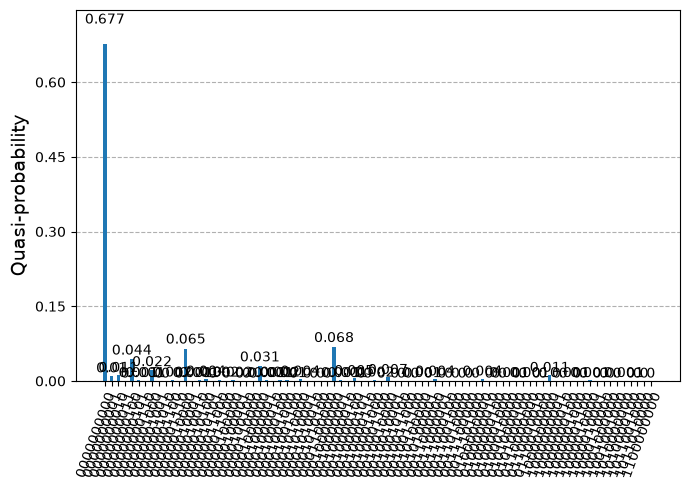

In [14]:
from qiskit.visualization import plot_distribution

plot_distribution(counts_bit)

あるいは、以下のような可視化を定義して、確率の高い上位10個の測定結果だけを見ることもできます。これはトラブルシューティングや、データについての直感を得るために重要になる場合があります。ただし、カーネル行列の要素はあくまでゼロ状態の測定確率です。



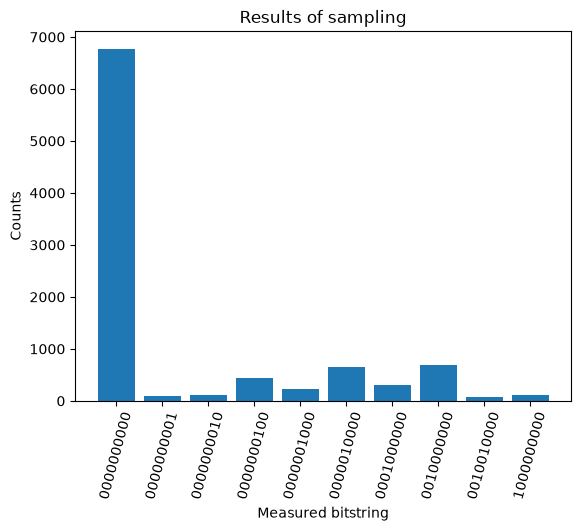

In [15]:
def visualize_counts(probs, num_qubits):
    """Qiskit の Sampler プリミティブの出力を可視化します。"""
    zero_prob = probs.get(0, 0.0)
    top_10 = dict(sorted(probs.items(), key=lambda item: item[1], reverse=True)[:10])
    top_10.update({0: zero_prob})
    by_key = dict(sorted(top_10.items(), key=lambda item: item[0]))
    xvals, yvals = list(zip(*by_key.items()))
    xvals = [bin(xval)[2:].zfill(num_qubits) for xval in xvals]
    plt.bar(xvals, yvals)
    plt.xticks(rotation=75)
    plt.title("Results of sampling")
    plt.xlabel("Measured bitstring")
    plt.ylabel("Counts")
    plt.show()


visualize_counts(counts, overlap_circ.num_qubits)

高次元の特徴量空間における2つのデータ点間の内積1つだけの情報からは、両者の重なりが最大の重なり（1.0）と比べてかなり大きいということしか言えません。これは、この2つのデータ点が何らかの意味で性質が似ており、同じクラスに分類されることを示しているのかもしれません。あるいは、似たデータどうしの重なりが大きく、似ていないデータどうしの重なりが小さくなるような空間へのマッピングとして、特徴量マップが効果的でないことを示しているのかもしれません。どちらが正しいかを知るには、特徴量マップをデータ全体に適用し、得られたカーネル行列を使って高い精度でクラスを効果的に分離できるかどうかを確かめる必要があります。

ここでは `z_feature_map` を使ったため、トランスパイル後の2量子ビット深さが小さく（実際には深さ1）なったことは注目に値します。回路が深くなりすぎると、必ず多くのノイズが生じ、たとえ特徴量マップがデータによく適合していても、ゼロ状態を測定する確率は非常に低くなってしまいます。例えば、同じデータ点に対して `zz_feature_map` と `, entanglement='linear', reps=1` を使って上記の処理を繰り返したところ、`dist.get(0,0.0) = 0.0015` という結果になりました。これは、`zz_feature_map` の回路の深さと2量子ビット深さがはるかに大きいためです。下の図は、その計算での確率分布を示しています。

![Bad results from a zz feature map.](https://quantum.cloud.ibm.com/learning/images/courses/quantum-machine-learning/quantum-kernel-methods/zzfeaturemap-bad-results.avif)

同じカテゴリーに属するいくつかのデータ点を使って試し、良い結果を得るために深さをどの程度まで小さくする必要があるかを調べてみる価値があります。以下は大まかな目安であり、例外も必ずあります。一般に、トランスパイル後の2量子ビット深さが10以下であれば問題はないはずです。トランスパイル後の2量子ビット深さが50〜60であれば最先端の水準であり、高度なエラー緩和をはじめとするさまざまなツールが必要になります。その中間では、データの類似度、特徴量マップの表現力、回路の幅などの要因によって結果が変わる可能性があります。



通常、後処理のステップには古典的な機械学習の処理も含まれます。次のセクションでは、この処理をデータセット全体に拡張し、古典的な機械学習のワークフローを示します。



#### 理解度チェック

10量子ビットの量子回路では、一般に、測定され得る異なる状態はいくつありますか？

<Accordion>
  <AccordionItem title="解答">
    $2^{10}$、すなわち1024です。
  </AccordionItem>
</Accordion>

量子コンピューティングの初心者が、2量子ビット深さが非常に大きい量子回路を、エラー緩和を使わずに使おうとしたとします。さらに、その結果として各量子ビットに10%のエラー率が生じたとします。この回路に対応する真の（エラーのない）カーネル行列の要素が非常に大きく、例えば1.0だった場合、10個すべての量子ビットが $|0\rangle$ である状態を測定する確率はどれくらいになるでしょうか？

<Accordion>
  <AccordionItem title="解答">
    各量子ビットが正しく |0> 状態で見つかる確率は0.90です。10個すべての量子ビットが正しい状態で見つかる確率は $0.90^{10}$、すなわち約35%です。
  </AccordionItem>
</Accordion>

回路の深さを監視することがなぜそれほど重要なのか、自分の言葉で説明してください。これは一般的に言えることですが、量子カーネル推定の文脈で説明してください。

<Accordion>
  <AccordionItem title="解答">
    この QKE ワークフローでは、推定値はゼロ状態、つまりすべての量子ビットが $|0\rangle$ 状態で見つかる状態の測定に基づいています。非常に深い回路は高いエラー率をもたらします。そのエラー率が多数の量子ビットにわたって積み重なると、ゼロ状態を測定する確率が大幅に低下します。
  </AccordionItem>
</Accordion>



## カーネル行列全体

このセクションでは、上記の処理をデータセット全体の二値分類に拡張します。これにより、2つの重要な要素が加わります。(1) 後処理で古典的な機械学習を実装できるようになること、(2) 訓練の精度スコアが得られるようになることです。

### ステップ1: 古典的な入力を量子問題にマッピングする

次に、分類用の既存のデータセットをインポートします。このデータセットは128行（データ点）から成り、各点には14個の特徴量があります。15番目の要素は、各点の二値カテゴリー（$\pm 1$）を示します。データセットは以下でインポートしますが、[こちら](https://github.com/qiskit-community/prototype-quantum-kernel-training/blob/main/data/dataset_graph7.csv)からデータセットにアクセスしてその構造を確認することもできます。

最初の90個のデータ点を訓練に、続く30個の点をテストに使います。



In [16]:
!wget https://raw.githubusercontent.com/qiskit-community/prototype-quantum-kernel-training/main/data/dataset_graph7.csv

df = pd.read_csv("dataset_graph7.csv", sep=",", header=None)

# 訓練データを準備

train_size = 90
X_train = df.values[0:train_size, :-1]
train_labels = df.values[0:train_size, -1]

# テストデータを準備
test_size = 30
X_test = df.values[train_size : train_size + test_size, :-1]
test_labels = df.values[train_size : train_size + test_size, -1]

--2026-10-30 23:14:18--  https://raw.githubusercontent.com/qiskit-community/prototype-quantum-kernel-training/main/data/dataset_graph7.csv
raw.githubusercontent.com (raw.githubusercontent.com) をDNSに問いあわせています... 2606:50c0:8000::154, 2606:50c0:8003::154, 2606:50c0:8002::154, ...
raw.githubusercontent.com (raw.githubusercontent.com)|2606:50c0:8000::154|:443 に接続しています... 接続しました。
HTTP による接続要求を送信しました、応答を待っています... 200 OK
長さ: 49405 (48K) [text/plain]
`dataset_graph7.csv' に保存中

dataset_graph7.csv  100%[===================>]  48.25K  --.-KB/s 時間 0.003s     

2026-10-30 23:14:19 (17.0 MB/s) - `dataset_graph7.csv' へ保存完了 [49405/49405]



複数の出力を格納する準備として、適切な次元のカーネル行列とテスト行列をあらかじめ作成しておきます。



In [17]:
# 空のカーネル行列
num_samples = np.shape(X_train)[0]
kernel_matrix = np.full((num_samples, num_samples), np.nan)
test_matrix = np.full((test_size, num_samples), np.nan)

次に、古典データを量子回路にエンコードしてマッピングするための特徴量マップを作成します。独自の特徴量マップを構成することも、既製のものを使うこともできます。以下の特徴量マップを自由に変更したり、ZFeatureMap に戻したりしてみてください。ただし、常に回路の深さに注意を払ってください。前の6量子ビットの例では、`zz_feature_map` を使うとトランスパイル後の回路の深さが手に負えないほど大きくなったことを思い出してください。回路の規模と複雑さが増すにつれて、深さは急速に増加し、ノイズが結果を圧倒してしまうほどになる可能性があります。データ構造について、どのような特徴量マップ構造が最も有用かを示唆する何らかの知見がある場合には、その知見を活用した独自のカスタム特徴量マップを作成することをお勧めします。



In [18]:
from qiskit.circuit import Parameter, ParameterVector, QuantumCircuit

# オーバーラップ計算用の特徴量マップを準備
num_features = np.shape(X_train)[1]
num_qubits = int(num_features / 2)

# カスタム特徴量マップを使う場合は、以下の行を使用します。
entangler_map = [[0, 2], [3, 4], [2, 5], [1, 4], [2, 3], [4, 6]]

fm = QuantumCircuit(num_qubits)
training_param = Parameter("θ")
feature_params = ParameterVector("x", num_qubits * 2)
fm.ry(training_param, fm.qubits)
for cz in entangler_map:
    fm.cz(cz[0], cz[1])
for i in range(num_qubits):
    fm.rz(-2 * feature_params[2 * i + 1], i)
    fm.rx(-2 * feature_params[2 * i], i)

### ステップ2と3: 問題を最適化し、プリミティブを使って実行する

オーバーラップ回路を構成します。この例で実際の量子コンピューター上で実行するのであれば、前と同様に実行向けに最適化することになります。しかし今回は、すべてのデータ点を順にたどってカーネル行列全体を計算するつもりです。データベクトルのペア $\vec{x}_i$ と $\vec{x}_j$ ごとに、異なるオーバーラップ回路を作成します。したがって、データ点のペアごとに回路を最適化する必要があります。そのため、ステップ2と3は繰り返しの中で一緒に行われることになります。

以下のコードセルは、前に1つのデータ点ペアに対して行ったのとまったく同じ処理を行います。今回は単にそれを2つの `for` ループの中で実行しており、各計算の結果を格納するために末尾に `kernel_matrix[x_1,x_2] = ...` という行が追加されています。カーネル行列の対称性を利用して、計算回数を1/2に減らしていることに注意してください。また、ノイズがない場合にそうなるべきであるように、対角要素は単純に1に設定しています。実装や必要な精度によっては、対角要素を使ってノイズを推定したり、エラー緩和の目的でノイズについて調べたりすることもできます。

カーネル行列がすべて埋まったら、テストデータに対して同じ処理を繰り返し、test\_matrix を埋めます。これも実際にはカーネル行列ですが、2つを区別するために別の名前を付けているだけです。



In [19]:
# シミュレーターを使う場合
from qiskit.primitives import StatevectorSampler

# 実際の量子コンピューターを使うには、QiskitRuntimeService のコンストラクターに
# トークンを入力することを忘れないでください

# service = QiskitRuntimeService()
# backend = service.least_busy(
#    operational=True, simulator=False, min_num_qubits=fm.num_qubits
# )

num_shots = 10000

# Qiskit の状態ベクトルベースのプリミティブを使って問題を評価します。
sampler = StatevectorSampler()

for x1 in range(0, train_size):
    for x2 in range(x1 + 1, train_size):
        unitary1 = fm.assign_parameters(list(X_train[x1]) + [np.pi / 2])
        unitary2 = fm.assign_parameters(list(X_train[x2]) + [np.pi / 2])

        # オーバーラップ回路を作成
        overlap_circ = unitary_overlap(unitary1, unitary2)
        overlap_circ.measure_all()

        # 以下の行で Qiskit の Sampler プリミティブを実行します。
        counts = (
            sampler.run([overlap_circ], shots=num_shots)
            .result()[0]
            .data.meas.get_int_counts()
        )

        # 0状態の確率をカーネル行列の要素と、その転置要素に代入します
        # （これは内積であるため）
        kernel_matrix[x1, x2] = counts.get(0, 0.0) / num_shots
        kernel_matrix[x2, x1] = counts.get(0, 0.0) / num_shots
    # 対角要素を1で埋めます。これも、確率に対応する内積であるためです
    # （あるいはコードを変更してこれらの要素を計算し、1になることを確認してください）
    kernel_matrix[x1, x1] = 1

print("training done")

# 上記と同様の処理を、テストデータに対して行います。
for x1 in range(0, test_size):
    for x2 in range(0, train_size):
        unitary1 = fm.assign_parameters(list(X_test[x1]) + [np.pi / 2])
        unitary2 = fm.assign_parameters(list(X_train[x2]) + [np.pi / 2])

        # オーバーラップ回路を作成
        overlap_circ = unitary_overlap(unitary1, unitary2)
        overlap_circ.measure_all()

        counts = (
            sampler.run([overlap_circ], shots=num_shots)
            .result()[0]
            .data.meas.get_int_counts()
        )

        test_matrix[x1, x2] = counts.get(0, 0.0) / num_shots

print("test matrix done")

training done
test matrix done


### ステップ4: 後処理を行い、結果を古典的な形式で返す

量子カーネル法によってカーネル行列と同様の形式の test\_matrix が得られたので、古典的な機械学習アルゴリズムを適用してテストデータについて予測を行い、その精度を確認できます。まず、サポートベクター分類器（SVC）である Scikit-Learn の `sklearn.svc` をインポートします。SVC に事前計算済みのカーネルを使わせることを、`kernel = precomputed` で指定する必要があります。



In [20]:
# 古典的な機械学習パッケージからサポートベクター分類器をインポートします。
from sklearn.svm import SVC

# 事前計算済みのカーネル行列を使うことを指定します
qml_svc = SVC(kernel="precomputed")

`SVC.fit` を使って、カーネル行列と訓練ラベルを入力し、フィッティングを行います。次に `SVC.score` が、test\_matrix を使ってテストデータをそのフィッティング結果に照らして評価し、精度を返します。



In [21]:
# 事前計算済みの行列と訓練データのラベルを入力します。
# 古典アルゴリズムによってフィッティングが得られます。
qml_svc.fit(kernel_matrix, train_labels)

# 次に .score を使い、テストデータの行列とテストラベルを入力として
# データをテストします。
qml_score_precomputed_kernel = qml_svc.score(test_matrix, test_labels)
print(f"Precomputed kernel classification test score: {qml_score_precomputed_kernel}")

Precomputed kernel classification test score: 1.0


訓練したモデルの精度は100%でした。これは素晴らしい結果であり、QKE が機能し得ることを示しています。しかし、それは量子優位性とはまったく別のものです。古典的なカーネルでも、おそらくこの分類問題を100%の精度で解くことができたでしょう。現在のユーティリティー時代において量子カーネルがどこで最も有用になるかを見極めるには、さまざまなデータの種類やデータ間の関係を特徴付ける多くの研究が必要です。
このワークフローの一部を変更して、さまざまな量子特徴量マップの有効性を調べることは学習者の皆さんにお任せします。検討すべき点をいくつか挙げます。

* 精度はどの程度頑健でしょうか？ 幅広い種類のデータで成り立つのでしょうか、それともこの特定の訓練データだけでしょうか？
* データのどのような構造から、量子特徴量マップが有用だと考えられるでしょうか？
* 訓練データの量を増減させると、精度はどのように影響を受けるでしょうか？
* どのような特徴量マップを使うことができ、特徴量マップによって結果はどのように変わるでしょうか？
* 特徴量の数を増やすと、精度と実行時間はどのように影響を受けるでしょうか？
* 実際の量子コンピューター上でも成り立つと予想される傾向があるとすれば、それはどれでしょうか？



## より多くの特徴量と量子ビットへのスケーリング

このセクションでは、行列要素1つの計算を繰り返しますが、特徴量の数をはるかに多くし、ユーティリティーに向けてスケールアップする道筋を示します。行列要素1つに限定しているのは、量子コンピューターの割り当て時間をあまり使い切らずに処理を示すためです。

### ステップ1: 古典的な入力を量子問題にマッピングする

各データ点が42個の特徴量を持つデータセットを出発点とします。最初の例と同様に、カーネル行列の要素を1つ計算するので、2つのデータ点が必要です。以下の2つの点は、42個の特徴量と1つのカテゴリー変数（$\pm 1$）を持っています。



In [22]:
# 訓練時と同様に、カテゴリーラベルを含む2つの模擬データ点

large_data = [
    [
        -0.028,
        -1.49,
        -1.698,
        0.107,
        -1.536,
        -1.538,
        -1.356,
        -1.514,
        -0.109,
        -1.8,
        -0.122,
        -1.651,
        -1.955,
        -0.123,
        -1.732,
        0.091,
        -0.048,
        -0.128,
        -0.026,
        0.082,
        -1.263,
        0.065,
        0.004,
        -0.055,
        -0.08,
        -0.173,
        -1.734,
        -0.39,
        -1.451,
        0.078,
        -1.578,
        -0.025,
        -0.184,
        -0.119,
        -1.336,
        0.055,
        -0.204,
        -1.578,
        0.132,
        -0.121,
        -1.599,
        -0.187,
        -1,
    ],
    [
        -1.414,
        -1.439,
        -1.606,
        0.246,
        -1.673,
        0.002,
        -1.317,
        -1.262,
        -0.178,
        -1.814,
        0.013,
        -1.619,
        -1.86,
        -0.25,
        -0.212,
        -0.214,
        -0.033,
        0.071,
        -0.11,
        -1.607,
        0.441,
        -0.143,
        -0.009,
        -1.655,
        -1.579,
        0.381,
        -1.86,
        -0.079,
        -0.088,
        -0.058,
        -1.481,
        -0.064,
        -0.065,
        -1.507,
        0.177,
        -0.131,
        -0.153,
        0.07,
        -1.627,
        0.593,
        -1.547,
        -0.16,
        -1,
    ],
]
train_data = [large_data[0][:-1], large_data[1][:-1]]

`zz_feature_map` は、特徴量が比較的少ない場合（14個の特徴量）でもかなり深い回路を生成したことを思い出してください。特徴量の数を増やすにつれて、回路の深さを注意深く監視する必要があります。これを示すために、まず `zz_feature_map` を使ってみて、得られる回路の深さを確認します。



In [23]:
from qiskit.circuit.library import zz_feature_map

fm = zz_feature_map(
    feature_dimension=np.shape(train_data)[1], entanglement="linear", reps=1
)

unitary1 = fm.assign_parameters(train_data[0])
unitary2 = fm.assign_parameters(train_data[1])

In [24]:
from qiskit.circuit.library import unitary_overlap


overlap_circ = unitary_overlap(unitary1, unitary2)
overlap_circ.measure_all()

print("circuit depth = ", overlap_circ.decompose(reps=2).depth())
print(
    "two-qubit depth",
    overlap_circ.decompose().depth(lambda instr: len(instr.qubits) > 1),
)
# overlap_circ.draw("mpl", scale=0.6, style="iqp")

circuit depth =  251
two-qubit depth 165


前にも述べたように、どの程度の深さなら深すぎるのかを正確に判断するのは微妙な問題です。しかし、トランスパイル前の時点ですでに2量子ビット深さが100を超えているようでは、まったく話になりません。このレッスン全体を通してカスタム特徴量マップを強調してきたのはこのためです。データセット全体の構造について何らかの知見があるなら、その構造を念頭に置いてエンタングルメント・マップを設計すべきです。ここでは、そのようなデータ点2つの間の内積を計算するだけなので、データ構造の詳細な検討よりも回路の深さを小さくすることを優先しています。



In [25]:
from qiskit.circuit import Parameter, ParameterVector, QuantumCircuit

# オーバーラップ計算用の特徴量マップを準備

entangler_map = [
    [3, 4],
    [2, 5],
    [1, 4],
    [2, 3],
    [4, 6],
    [7, 9],
    [10, 11],
    [9, 12],
    [8, 11],
    [9, 10],
    [11, 13],
    [14, 16],
    [17, 18],
    [16, 19],
    [15, 18],
    [16, 17],
    [18, 20],
]

In [26]:
# 上のエンタングラー・マップを使って特徴量マップを構築

num_features = np.shape(train_data)[1]
num_qubits = int(num_features / 2)

fm = QuantumCircuit(num_qubits)
training_param = Parameter("θ")
feature_params = ParameterVector("x", num_qubits * 2)
fm.ry(training_param, fm.qubits)
for cz in entangler_map:
    fm.cz(cz[0], cz[1])
for i in range(num_qubits):
    fm.rz(-2 * feature_params[2 * i + 1], i)
    fm.rx(-2 * feature_params[2 * i], i)

In [27]:
from qiskit.circuit.library import unitary_overlap

# 各データ点の特徴量を、一般的な特徴量マップのインスタンスであるユニタリーに割り当てます。

unitary1 = fm.assign_parameters(list(train_data[0]) + [np.pi / 2])
unitary2 = fm.assign_parameters(list(train_data[1]) + [np.pi / 2])

# オーバーラップ回路を作成

overlap_circ = unitary_overlap(unitary1, unitary2)
overlap_circ.measure_all()

重要なのはトランスパイル後の2量子ビット深さなので、ここではまだ深さを確認しません。



### ステップ2: 量子実行向けに問題を最適化する

まず最も空いているバックエンドを選択し、そのバックエンドで実行できるように回路を最適化します。



In [28]:
# 必要なパッケージをインポート
from qiskit.transpiler.preset_passmanagers import generate_preset_pass_manager
from qiskit_ibm_runtime import QiskitRuntimeService

# 最も空いているバックエンドを取得
service = QiskitRuntimeService()
backend = service.least_busy(
    operational=True, simulator=False, min_num_qubits=fm.num_qubits
)
print(backend)

<IBMBackend('ibm_fez')>


小規模なジョブでは、プリセット・パス・マネージャーは多くの場合、同じ深さの同じ回路を確実に返します。しかし、非常に大規模で複雑な回路では、パス・マネージャーは実行するたびに異なるトランスパイル済み回路を返すことがあります。これは、パス・マネージャーがヒューリスティクスを用いており、また非常に大規模な回路では可能な最適化の地形が複雑になるためです。何回かトランスパイルを行い、最も浅い回路を採用すると役立つことがよくあります。これによって生じるのは古典的なオーバーヘッドのみであり、量子コンピューターから得られる結果が大幅に改善される可能性があります。

ここでは、ユニタリー・オーバーラップ回路を20回トランスパイルし、得られた回路の深さを確認します。



In [29]:
# オーバーラップ回路にレベル3の最適化を適用
transpiled_qcs = []
transpiled_depths = []
transpiled_twoqubit_depths = []
for i in range(1, 20):
    pm = generate_preset_pass_manager(optimization_level=3, backend=backend)
    overlap_ibm = pm.run(overlap_circ)
    transpiled_qcs.append(overlap_ibm)
    transpiled_depths.append(overlap_ibm.decompose().depth())
    transpiled_twoqubit_depths.append(
        overlap_ibm.decompose().depth(lambda instr: len(instr.qubits) > 1)
    )

print("circuit depth = ", overlap_ibm.decompose().depth())

circuit depth =  39


In [30]:
print(transpiled_depths)
print(transpiled_twoqubit_depths)

[39, 39, 39, 39, 39, 39, 39, 39, 39, 39, 39, 39, 39, 39, 39, 39, 39, 39, 39]
[7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7, 7]


ここから、トランスパイルの実行ごとに全体のゲート深さにいくらかのばらつきがあることがわかります。この回路はまだ、トランスパイル後の2量子ビット深さにばらつきが見られるほど深く/幅広くはありません。ここでは `transpiled_qcs[1]` を使います。その深さは60で、得られた中で最も深い回路の深さ77よりもわずかに小さくなっています。



In [31]:
overlap_ibm = transpiled_qcs[1]

### ステップ3: IBM Quantum primitives を使って実行する

ユーティリティー規模に近づくにつれて、シミュレーターは役に立たなくなります。ここでは、実際の量子コンピューター向けの構文のみを示します。



In [32]:
# ibm_osaka で実行（2024年7月12日）、所要時間22秒。

# IBM Quantum のプリミティブをインポート
from qiskit_ibm_runtime.executor_sampler import Sampler

# セッションを開く:
session = Session(backend=backend)
num_shots = 10000
# Sampler を使ってカウントを取得

sampler = Sampler(mode=session)
options = sampler.options
options.dynamical_decoupling.enable = True
options.twirling.enable_gates = True
counts = (
    sampler.run([overlap_ibm], shots=num_shots).result()[0].data.meas.get_int_counts()
)

# 完了後にセッションを閉じる
session.close()

### ステップ4: 後処理を行い、結果を古典的な形式で返す

導入で説明したように、ここで最も有用な測定値はゼロ状態 $|00000\rangle$ を測定する確率です。



In [33]:
counts.get(0, 0.0) / num_shots

0.0234

この単一のカーネル行列要素を求める処理を、データセット内の他のデータペアについても繰り返すことで、カーネル行列全体が得られます。カーネル行列の次元は、特徴量の数ではなく、訓練データの点の数によって決まります。そのため、カーネル行列を処理して予測モデルを作る計算コストは、特徴量や量子ビットの数に応じて増えるわけではありません。特徴量の数が多い比較的小さなデータセットであっても、効果的な分類をもたらす特徴量マップにデータを適合させる必要があることに変わりはありません。

### スケーリングと今後の課題

カーネル法では、$|0\rangle$ をできるだけ正確に測定する必要があります。しかし、ゲートエラーや読み出しエラーにより、任意の量子ビットが誤って $|1\rangle$ 状態として測定されるゼロでない確率 $p$ が存在します。$|0\rangle$ の確率は $100\%$ であるべきだと単純化したとしても、多数の特徴量を例えば $N$ ビットにエンコードした場合、すべてのビットを正しく $|0\rangle$ と測定する確率は $(1-p)^N$ に低下します。$N$ が大きくなるにつれて、この手法の信頼性はますます低くなります。この困難を克服し、カーネル推定をより多くの特徴量へとスケールさせることは、現在研究が進められている分野です。この問題について詳しく知るには、[Thanasilp, Wang, Cerezo, and Holmes](https://www.nature.com/articles/s41467-024-49287-w) による研究をご覧ください。現在の量子コンピューターで何ができるかを探求するとともに、誤り訂正の時代に何が可能になるかにも期待してください。



### まとめ

量子カーネルの計算には、次のことが含まれます。

* 訓練データ点のペアを使ってカーネル行列の要素を計算すること
* データをエンコードし、特徴量マップによってマッピングすること
* 実際の量子コンピューター/バックエンドで実行できるように回路を最適化すること

このレッスンで行ったように、量子カーネルは古典的な機械学習アルゴリズムで使うことができます。

量子カーネルを使う際に留意すべき重要な点には、次のようなものがあります。

* そのデータセットは量子カーネル法の恩恵を受けられそうか？
* さまざまな特徴量マップやエンタングルメントの方式を試す。
* 回路の深さは許容範囲内か？
* パス・マネージャーを複数回実行し、得られる中で最も深さの小さい回路を使う。

量子カーネル法は、量子に適した特徴を持つデータセットと、適切な量子特徴量マップとがうまく組み合わされれば、強力なツールになる可能性があります。量子カーネルがどこで有用になりそうかをより深く理解するために、[Liu, Arunachalam & Temme (2021)](https://www.nature.com/articles/s41567-021-01287-z) を読むことをお勧めします。



© IBM Corp., 2017-2026